# Project 07: Impact risk explorer

**Question:** Which known asteroids could still hit Earth, and how did 2024 YR4 go from a ~3% chance of hitting Earth to a near miss of the Moon?

**Data source:** NASA/JPL Center for Near-Earth Object Studies (CNEOS), *Sentry* impact-monitoring system, through the Sentry Data API:
https://ssd-api.jpl.nasa.gov/doc/sentry.html (anonymous access, no sign-up).

Sentry keeps a list of asteroids whose orbits allow a possible Earth impact in the next ~100 years.
When new observations shrink the uncertainty in an orbit enough to rule out every impact, the object is **removed** from the list.

This notebook has three parts:
1. **The risk table:** every object currently on the list.
2. **Removals:** when objects get taken off the list, and how long they stayed on it.
3. **2024 YR4 timeline:** how one famous asteroid's risk rose and fell.

In [1]:
import os, re
import requests
import pandas as pd
import matplotlib.pyplot as plt

API = 'https://ssd-api.jpl.nasa.gov/sentry.api'
os.makedirs('../data', exist_ok=True)    # downloaded data lives here (git-ignored)
os.makedirs('../plots', exist_ok=True)   # figures we save for GitHub

## 1. The Sentry risk table

We download the current list and save a copy to `data/` (a few hundred kB).
Each row is one asteroid. The most useful columns:

| column | meaning |
|---|---|
| `fullname` | the asteroid's name or designation |
| `ip` | cumulative impact probability (sum over all possible impact dates) |
| `ps_cum` | Palermo scale: risk compared with the normal "background" risk from random asteroids. Below −2 means no concern; above 0 means it deserves attention |
| `ts_max` | Torino scale (0–10), the public-facing hazard rating. 0 = no hazard |
| `diameter` | estimated size in **km** (estimated from brightness, so it's approximate) |
| `range` | the years in which an impact is possible |
| `n_imp` | how many possible impact dates Sentry found |

In [2]:
resp = requests.get(API, timeout=60)
resp.raise_for_status()                          # stop with a clear error if the download failed
sentry = pd.DataFrame(resp.json()['data'])
sentry.to_csv('../data/sentry_current.csv', index=False)

# The API sends numbers as text, so convert the columns we use
for col in ['ip', 'ps_cum', 'ps_max', 'ts_max', 'diameter', 'h', 'v_inf', 'n_imp']:
    sentry[col] = pd.to_numeric(sentry[col], errors='coerce')
sentry['fullname'] = sentry['fullname'].str.strip()
sentry['first_year'] = sentry['range'].str[:4].astype(int)    # first year an impact is possible

print(f"{len(sentry)} objects are on the Sentry list right now.")
print(f"Objects with Torino scale above 0: {(sentry['ts_max'] > 0).sum()}")
print(f"Objects with Palermo scale above -2: {(sentry['ps_cum'] > -2).sum()}")

2251 objects are on the Sentry list right now.
Objects with Torino scale above 0: 0
Objects with Palermo scale above -2: 2


The 10 objects with the highest Palermo scale (the ones that matter most, all things considered):

In [3]:
cols = ['fullname', 'ip', 'ps_cum', 'ts_max', 'diameter', 'range', 'n_imp', 'last_obs']
sentry.sort_values('ps_cum', ascending=False)[cols].head(10).reset_index(drop=True)

,fullname,ip,ps_cum,ts_max,diameter,range,n_imp,last_obs
0,29075 (1950 DA),3.401000e-04,-0.98,NaN,1.3000,2880-2880,1,2026-11-05
1,101955 Bennu (1999 RQ36),5.717000e-04,-1.40,NaN,0.4900,2178-2290,157,2020-10-3.80160
2,(2008 JL3),1.658148e-04,-2.38,0.0,0.0290,2027-2122,44,2008-05-09
3,(1979 XB),8.515158e-07,-2.69,0.0,0.6600,2056-2113,4,1979-12-15
4,(2000 SG344),2.743395e-03,-2.76,0.0,0.0370,2069-2122,300,2000-10-03
5,(2010 RF12),1.026373e-01,-2.96,0.0,0.0071,2095-2122,70,2022-08-24
6,(2007 FT3),7.744342e-07,-3.00,0.0,0.3410,2030-2119,87,2007-03-21
7,(2022 PX1),3.231000e-06,-3.07,0.0,0.1200,2040-2040,1,2022-08-12
8,(2005 QK76),7.054525e-05,-3.10,0.0,0.0310,2030-2059,6,2005-08-31
9,(2021 GX9),8.222347e-05,-3.18,0.0,0.0290,2032-2052,2,2021-04-17


### Figure 1: impact probability vs. Palermo scale

This is the starter's plot, made a bit clearer: the colour shows the first year an impact is possible.
Big asteroids sit **higher** at the same probability, because the Palermo scale weighs how much damage an impact would do.

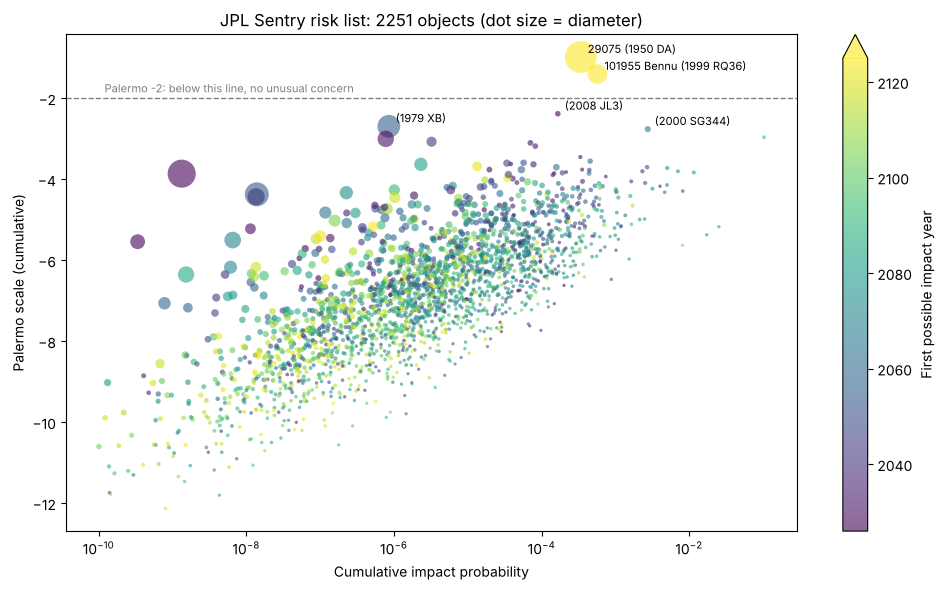

In [4]:
fig, ax = plt.subplots(figsize=(10, 6))
sc = ax.scatter(sentry['ip'], sentry['ps_cum'],
                s=5 + 400 * sentry['diameter'].fillna(0),   # dot area grows with diameter
                c=sentry['first_year'], cmap='viridis', vmax=2125,   # cap colours: 1950 DA (year 2880) would wash out the rest
                alpha=0.6, edgecolor='none')
for _, row in sentry.nlargest(5, 'ps_cum').iterrows():
    ax.annotate(row['fullname'], (row['ip'], row['ps_cum']), fontsize=8,
                xytext=(5, 3), textcoords='offset points')
ax.axhline(-2, color='grey', ls='--', lw=1)
ax.text(1.2e-10, -1.85, 'Palermo -2: below this line, no unusual concern', fontsize=8, color='grey')
ax.set_xscale('log')
ax.set_xlabel('Cumulative impact probability')
ax.set_ylabel('Palermo scale (cumulative)')
ax.set_title(f'JPL Sentry risk list: {len(sentry)} objects (dot size = diameter)')
fig.colorbar(sc, label='First possible impact year', extend='max')
fig.tight_layout()
fig.savefig('../plots/07_sentry_risk_by_year.png', dpi=150)
plt.show()

## 2. Removals: how quickly do "threats" disappear?

The API's `?removed=1` option lists every object that has been taken off the list, with the date it was removed.

In [5]:
resp = requests.get(API, params={'removed': 1}, timeout=60)
resp.raise_for_status()
removed = pd.DataFrame(resp.json()['data'])
removed.to_csv('../data/sentry_removed.csv', index=False)
removed['removed'] = pd.to_datetime(removed['removed'])
print(f"{len(removed)} objects have been removed from the Sentry list.")
print(f"Oldest removal in the list: {removed['removed'].min():%Y-%m-%d}; newest: {removed['removed'].max():%Y-%m-%d}")
removed.head()

3600 objects have been removed from the Sentry list.
Oldest removal in the list: 2002-01-15; newest: 2026-11-16


,removed,des
0,2026-11-16 15:32:08,2026 VY15
1,2026-11-16 15:28:03,2026 VC6
2,2026-11-16 14:48:24,2026 VA1
3,2026-11-11 15:44:45,2026 OA3
4,2026-11-08 14:24:05,2026 VC3


How long did each object stay on the list? The API doesn't tell us when an object was *added*,
but most asteroids have a **provisional designation** that starts with the year they were discovered (e.g. `2024 YR4` → 2024).
So (removal year − discovery year) is a rough measure of how long it took to rule out an impact.
Objects with only a number, or an old survey name like `6344 P-L`, are skipped.

In [6]:
def discovery_year(des):
    # '2024 YR4' -> 2024. Numbers like '99942' and old survey names like '6344 P-L' -> None
    m = re.match(r'^((?:19|20)\d\d) [A-Z]{2}', str(des))
    return int(m.group(1)) if m else None

removed['disc_year'] = removed['des'].apply(discovery_year)
removed['years_to_removal'] = removed['removed'].dt.year - removed['disc_year']
dated = removed.dropna(subset=['disc_year'])
print(f"{len(dated)} of {len(removed)} removed objects have a year in their designation.")
same_year = (dated['years_to_removal'] == 0).mean()
print(f"{same_year:.0%} were removed in the same calendar year they were discovered.")

3592 of 3600 removed objects have a year in their designation.
79% were removed in the same calendar year they were discovered.


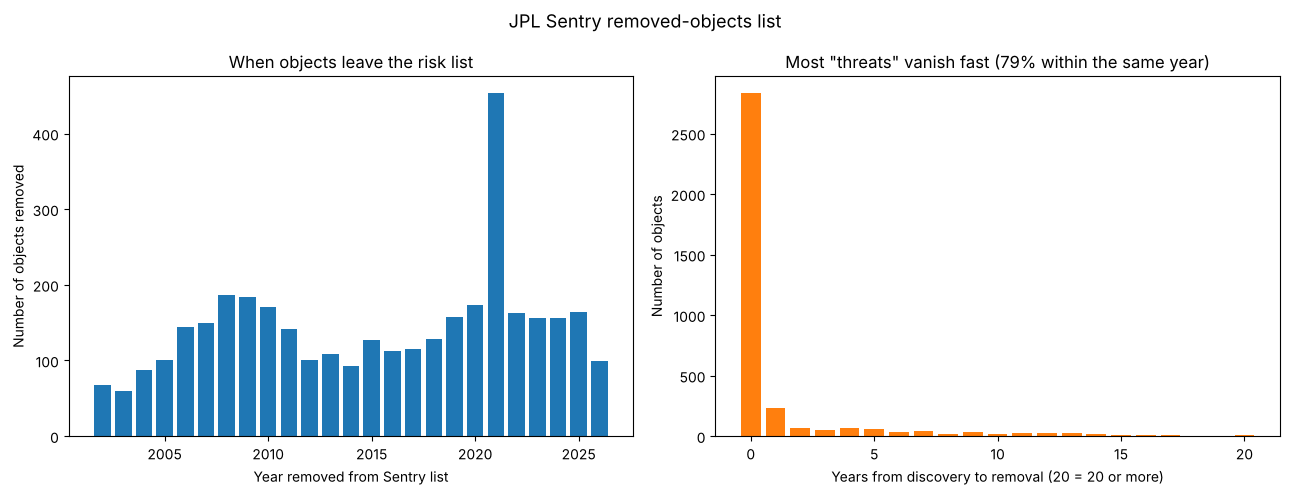

In [7]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

# Left: removals per year
by_year = removed['removed'].dt.year.value_counts().sort_index()
ax1.bar(by_year.index, by_year.values, color='tab:blue')
ax1.set_xlabel('Year removed from Sentry list')
ax1.set_ylabel('Number of objects removed')
ax1.set_title('When objects leave the risk list')

# Right: years between discovery and removal
counts = dated['years_to_removal'].clip(upper=20).value_counts().sort_index()
ax2.bar(counts.index, counts.values, color='tab:orange')
ax2.set_xlabel('Years from discovery to removal (20 = 20 or more)')
ax2.set_ylabel('Number of objects')
ax2.set_title(f'Most "threats" vanish fast ({same_year:.0%} within the same year)')

fig.suptitle('JPL Sentry removed-objects list', fontsize=13)
fig.tight_layout()
fig.savefig('../plots/07_sentry_removals.png', dpi=150)
plt.show()

## 3. Case study: 2024 YR4

First, ask the API directly what the asteroid's status is today.

In [8]:
yr4 = requests.get(API, params={'des': '2024 YR4'}, timeout=60).json()
yr4_removed = pd.to_datetime(yr4['removed']) if 'removed' in yr4 else None
print(yr4)

{'signature': {'version': '2.0', 'source': 'NASA/JPL Sentry Data API'}, 'error': 'specified object removed', 'removed': '2026-03-05 16:02:50'}


The API only reports **today's** status, not the history of the risk. The milestones below are typed in by hand from
NASA and ESA public announcements, with a source for each row.
**Before the demo, check each number against its source link**, because news updates were frequent and some were rounded.
The Sentry removal date comes straight from the API call above.

In [9]:
milestones = pd.DataFrame([
    # date,        target,  probability (%), what happened,                                         source
    ('2024-12-27', None,    None, 'Discovered by ATLAS telescope in Chile',                             'https://science.nasa.gov/blogs/planetary-defense/'),
    ('2025-01-29', 'Earth', 1.3,  'Passes 1% Earth-impact threshold; first IAWN notice',                'https://science.nasa.gov/blogs/planetary-defense/'),
    ('2025-02-18', 'Earth', 3.1,  'Peak Earth-impact probability for 22 Dec 2032 (Torino 3)',           'https://science.nasa.gov/blogs/planetary-defense/'),
    ('2025-02-24', 'Earth', 0.004,'New observations: Earth impact essentially ruled out',               'https://science.nasa.gov/blogs/planetary-defense/'),
    ('2025-06-05', 'Moon',  4.3,  'JWST observations refine orbit: Moon-impact chance ~4%',             'https://science.nasa.gov/blogs/planetary-defense/'),
    ('2026-02-15', 'Moon',  None, 'JWST observations in Feb 2026 rule out a 2032 Moon impact',          'PROJECTS.md brief; check NASA blog for exact date'),
], columns=['date', 'target', 'prob_pct', 'event', 'source'])
milestones['date'] = pd.to_datetime(milestones['date'])
milestones

,date,target,prob_pct,event,source
0,2024-12-27,None,NaN,Discovered by ATLAS telescope in Chile,https://science.nasa.gov/blogs/planetary-defense/
1,2025-01-29,Earth,1.300,Passes 1% Earth-impact threshold; first IAWN n...,https://science.nasa.gov/blogs/planetary-defense/
2,2025-02-18,Earth,3.100,Peak Earth-impact probability for 22 Dec 2032 ...,https://science.nasa.gov/blogs/planetary-defense/
3,2025-02-24,Earth,0.004,New observations: Earth impact essentially rul...,https://science.nasa.gov/blogs/planetary-defense/
4,2025-06-05,Moon,4.300,JWST observations refine orbit: Moon-impact ch...,https://science.nasa.gov/blogs/planetary-defense/
5,2026-02-15,Moon,NaN,JWST observations in Feb 2026 rule out a 2032 ...,PROJECTS.md brief; check NASA blog for exact date


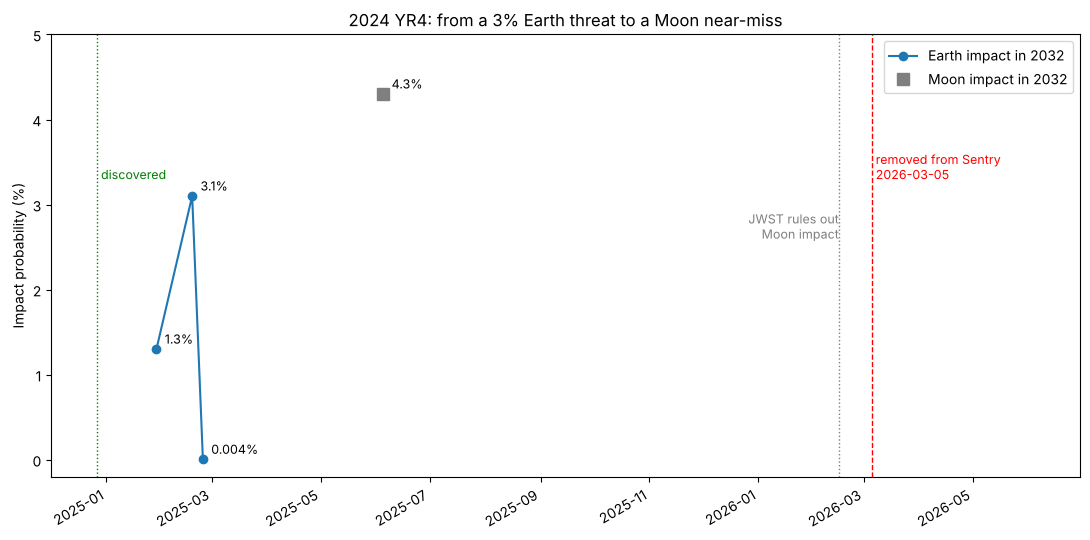

In [10]:
fig, ax = plt.subplots(figsize=(11, 5.5))

earth = milestones[milestones['target'] == 'Earth']
moon = milestones[(milestones['target'] == 'Moon') & milestones['prob_pct'].notna()]
ax.plot(earth['date'], earth['prob_pct'], 'o-', color='tab:blue', label='Earth impact in 2032')
ax.plot(moon['date'], moon['prob_pct'], 's', color='tab:grey', ms=8, label='Moon impact in 2032')

# Vertical lines for events that have no probability value
ax.axvline(milestones['date'].iloc[0], color='green', ls=':', lw=1)
ax.text(milestones['date'].iloc[0], 3.3, ' discovered', color='green', fontsize=9)
ax.axvline(milestones['date'].iloc[-1], color='tab:grey', ls=':', lw=1)
ax.text(milestones['date'].iloc[-1], 2.6, ' JWST rules out\n Moon impact', color='tab:grey', fontsize=9, ha='right')
if yr4_removed is not None:
    ax.axvline(yr4_removed, color='red', ls='--', lw=1)
    ax.text(yr4_removed, 3.3, f' removed from Sentry\n {yr4_removed:%Y-%m-%d}', color='red', fontsize=9)

for _, r in milestones.dropna(subset=['prob_pct']).iterrows():
    ax.annotate(f"{r['prob_pct']:g}%", (r['date'], r['prob_pct']), xytext=(6, 4),
                textcoords='offset points', fontsize=9)

ax.set_ylim(-0.2, 5)
ax.set_xlim(pd.Timestamp('2024-12-01'), pd.Timestamp('2026-06-30'))
ax.set_ylabel('Impact probability (%)')
ax.set_title('2024 YR4: from a 3% Earth threat to a Moon near-miss')
ax.legend(loc='upper right')
fig.autofmt_xdate()
fig.tight_layout()
fig.savefig('../plots/07_yr4_timeline.png', dpi=150)
plt.show()

## What we learned

- Thousands of objects are on the Sentry list, but almost all have tiny probabilities and Palermo scales far below −2.
- Most objects get removed soon after discovery, once a few more nights (or a few archival images) pin down the orbit.
  A short observation arc means a wide range of possible orbits, and some of those may cross Earth; more data narrows the range.
- 2024 YR4 followed exactly this pattern, just more publicly: its risk rose while the orbit was still uncertain and Earth stayed inside the shrinking range, then dropped to almost zero once Earth fell outside it.

**Data:** NASA/JPL CNEOS Sentry Data API, https://ssd-api.jpl.nasa.gov/doc/sentry.html. YR4 milestones from NASA Planetary Defense blog updates.